# Lab 4: Evaluating a Classifier

Applies the main classification metrics to the banknote authentication models from [Lab 3](../lab-03-decision-trees-random-forests/): a decision tree and a random forest.

Metrics covered: accuracy, confusion matrix, precision, recall, F1 (and F-beta), ROC curve and AUC, plus a feature importance activity.

**Positive class:** 1 = forged banknote. A false negative is a forgery that slips through.

## Setup: recreate last week's models

Same data, same 80/20 split and same random seed as Lab 3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dataset = pd.read_csv('bill_authentication.csv')
X = dataset.drop('Class', axis=1)
y = dataset['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

classifier = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

predictions = classifier.predict(X_test)
forest_predictions = forest.predict(X_test)

## 1. Accuracy

Accuracy is only trustworthy when the classes are roughly balanced, so check that first.

In [2]:
print(y.value_counts().rename({0: 'Genuine (0)', 1: 'Forged (1)'}))
print(f"\nForged share: {y.mean():.1%}")

Class
Genuine (0)    762
Forged (1)     610
Name: count, dtype: int64

Forged share: 44.5%


The classes are reasonably balanced (about 44% forged), so accuracy is a fair headline metric here.

In [3]:
from sklearn.metrics import accuracy_score

print(f"Accuracy of the decision tree is: {accuracy_score(y_test, predictions):.4f}")
print(f"Accuracy of the random forest is: {accuracy_score(y_test, forest_predictions):.4f}")

Accuracy of the decision tree is: 0.9818
Accuracy of the random forest is: 0.9927


### Why accuracy alone can mislead

A 'model' that always predicts the most common class still scores well above zero. On a heavily imbalanced dataset (e.g. 95/5) the same trick would score 95% while catching no positives at all.

In [4]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f"Always-predict-genuine accuracy: {accuracy_score(y_test, dummy.predict(X_test)):.4f}  (catches 0 forgeries)")

Always-predict-genuine accuracy: 0.5382  (catches 0 forgeries)


## 2. Confusion matrix

[[148   0]
 [  5 122]]


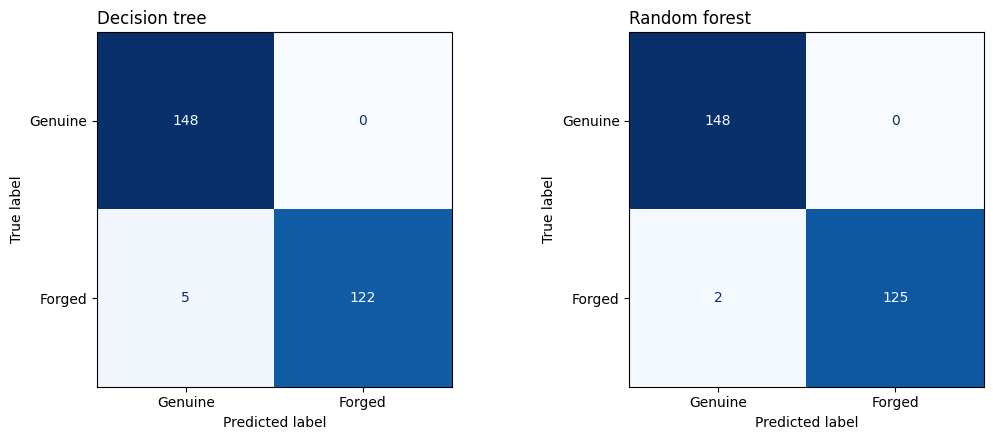

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

print(confusion_matrix(y_test, predictions))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, name in [(axes[0], classifier, 'Decision tree'), (axes[1], forest, 'Random forest')]:
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=['Genuine', 'Forged'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name, loc='left')
plt.tight_layout()
plt.show()

In [6]:
tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
print(f"Decision tree: TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"-> {fn} forged notes were wrongly accepted as genuine; {fp} genuine notes were wrongly flagged.")

Decision tree: TN=148  FP=0  FN=5  TP=122
-> 5 forged notes were wrongly accepted as genuine; 0 genuine notes were wrongly flagged.


## 3. Precision

Of the notes flagged as forged, how many really were? Precision = TP / (TP + FP).

In [7]:
from sklearn.metrics import precision_score

print(f"Precision Score of the classifier is: {precision_score(y_test, predictions):.4f}")
print(f"Check by hand: {tp} / ({tp} + {fp}) = {tp / (tp + fp):.4f}")

Precision Score of the classifier is: 1.0000
Check by hand: 122 / (122 + 0) = 1.0000


## 4. Recall

Of the notes that really were forged, how many did we catch? Recall = TP / (TP + FN).

In [8]:
from sklearn.metrics import recall_score

print(f"Recall Score of the classifier is: {recall_score(y_test, predictions):.4f}")
print(f"Check by hand: {tp} / ({tp} + {fn}) = {tp / (tp + fn):.4f}")

Recall Score of the classifier is: 0.9606
Check by hand: 122 / (122 + 5) = 0.9606


## 5. F1 and F-beta

F1 is the harmonic mean of precision and recall. For forgery detection a missed forgery (FN) is worse than a false alarm (FP), so **F2** (β = 2), which weights recall more heavily, is arguably the better single metric.

In [9]:
from sklearn.metrics import f1_score, fbeta_score

print(f"F1 Score of the classifier is: {f1_score(y_test, predictions):.4f}")
print(f"F2 Score (recall-weighted):    {fbeta_score(y_test, predictions, beta=2):.4f}")

F1 Score of the classifier is: 0.9799
F2 Score (recall-weighted):    0.9683


### All metrics side by side

In [10]:
def scores(pred):
    return [accuracy_score(y_test, pred), precision_score(y_test, pred), recall_score(y_test, pred),
            f1_score(y_test, pred), fbeta_score(y_test, pred, beta=2)]

summary = pd.DataFrame({'Decision tree': scores(predictions), 'Random forest': scores(forest_predictions)},
                       index=['Accuracy', 'Precision', 'Recall', 'F1', 'F2'])
summary.round(4)

,Decision tree,Random forest
Accuracy,0.9818,0.9927
Precision,1.0000,1.0000
Recall,0.9606,0.9843
F1,0.9799,0.9921
F2,0.9683,0.9874


## 6. ROC curve and AUC

The ROC curve plots the true positive rate against the false positive rate as the decision threshold moves from 1 to 0. AUC summarises it: 1.0 is perfect, 0.5 is no better than guessing.

AUC for the decision tree is: 0.9803  (3 thresholds)
AUC for the random forest is: 0.9999  (23 thresholds)


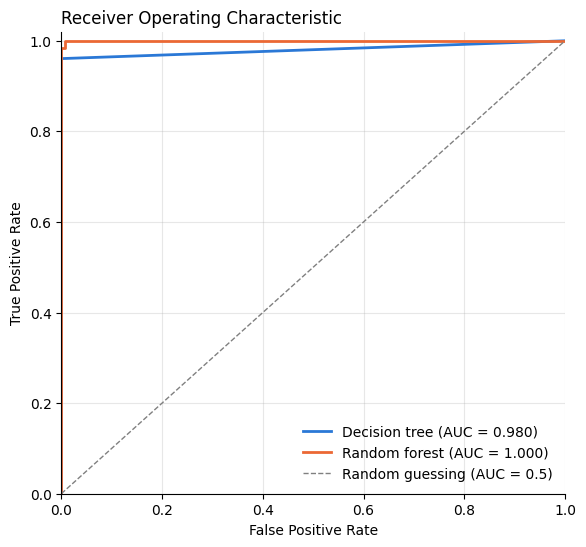

In [11]:
from sklearn.metrics import roc_curve, auc

fig, ax = plt.subplots(figsize=(6.5, 6))
for model, name, colour in [(classifier, 'Decision tree', '#2a78d6'), (forest, 'Random forest', '#eb6834')]:
    class_probabilities = model.predict_proba(X_test)
    preds = class_probabilities[:, 1]
    fpr, tpr, threshold = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)
    print(f"AUC for the {name.lower()} is: {roc_auc:.4f}  ({len(threshold)} thresholds)")
    ax.plot(fpr, tpr, color=colour, linewidth=2, label=f'{name} (AUC = {roc_auc:.3f})')

ax.plot([0, 1], [0, 1], color='grey', linestyle='--', linewidth=1, label='Random guessing (AUC = 0.5)')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Receiver Operating Characteristic', loc='left')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower right', frameon=False)
plt.show()

The decision tree's curve is just a couple of straight segments: a fully grown tree outputs probabilities of only 0 or 1, so there are very few thresholds to sweep. The random forest averages 100 trees, giving smooth probabilities and a proper curve.

## 7. Activity: feature importance

**Method: permutation importance.** Shuffle one feature's values in the test set and measure how much accuracy drops. A big drop means the model relies on that feature. Unlike the tree's built-in importance, this is measured on unseen data, directly from the classification results.

In [12]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(forest, X_test, y_test, n_repeats=30, random_state=42, scoring='accuracy')
perm_imp = pd.Series(perm.importances_mean, index=X.columns)
perm_std = pd.Series(perm.importances_std, index=X.columns)
builtin_imp = pd.Series(forest.feature_importances_, index=X.columns)

pd.DataFrame({'Permutation (accuracy drop)': perm_imp, '± std': perm_std,
              'Built-in (impurity)': builtin_imp}).sort_values('Permutation (accuracy drop)', ascending=False).round(4)

,Permutation (accuracy drop),± std,Built-in (impurity)
Variance,0.3206,0.0267,0.5651
Skewness,0.2447,0.0183,0.2276
Curtosis,0.1181,0.0133,0.1530
Entropy,0.0017,0.0018,0.0543


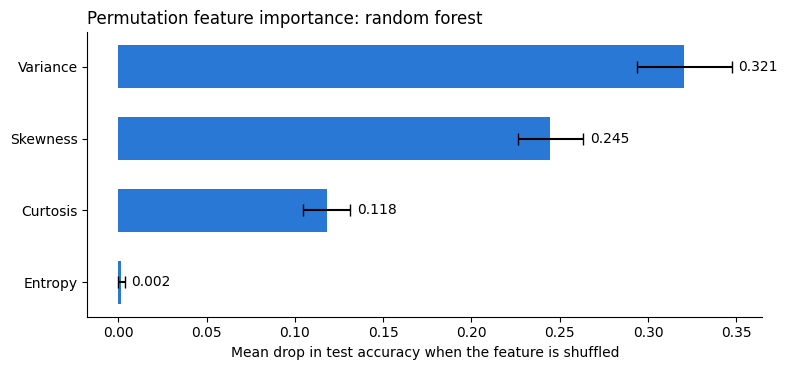

In [13]:
order = perm_imp.sort_values().index

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(order, perm_imp[order], xerr=perm_std[order], color='#2a78d6', height=0.6, capsize=4)
for i, f in enumerate(order):
    ax.text(perm_imp[f] + perm_std[f] + 0.004, i, f'{perm_imp[f]:.3f}', va='center')
ax.set_xlabel('Mean drop in test accuracy when the feature is shuffled')
ax.set_title('Permutation feature importance: random forest', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## Findings

- **Both models are excellent, and the random forest is better on every metric** (accuracy 99.3% vs 98.2%, AUC 0.9999 vs 0.980).
- **Precision is perfect for both:** no genuine note was ever flagged as forged.
- **The weak spot is recall:** the decision tree let 5 of 127 forgeries through (recall 96.1%), and the forest let 2 through (98.4%). For a forgery detector these false negatives are the costly error, so recall and F2 matter more than accuracy here.
- **Accuracy is a fair metric for this dataset** because the classes are fairly balanced (44.5% forged). The always-predict-genuine baseline only reaches 53.8%.
- **Feature importance:** Variance matters most, followed by Skewness and Curtosis. Entropy contributes almost nothing; shuffling it barely changes accuracy. Permutation and built-in importance agree on the ranking, but the built-in method gives Entropy more credit (5%) than it earns on unseen data (0.2%).